# U01b — Joint Unique × temporal-control test with full OG context

Goal: verify that the established **Unique prefix-control mechanism** and the temporal self-history intervention work together.

Frozen design:

- generator: `meta-llama/Llama-3.2-3B-Instruct`
- 20 frozen U01 prompts
- context: **WITH_PREV only**
- the entire original task + entire OG AI answer are always present and are **never temporally suppressed**
- only the newly generated self-history is attenuated
- Unique intervention: canonical C02w2/C02r prefix controller, including its human prefix curves and safeguards
- temporal arms:
  - `FULL`
  - `SIG_EARLY75`
  - `RECOVER`
  - `LINEAR75`
- `MAX_NEW_TOKENS = 640`
- total: **20 × 4 = 80 generations**

The notebook checkpoints every generation and initially reports status / Unique-control behavior without printing generated passages.

Important status semantics from U01a onward:

- `eos` = model terminated normally
- `truncated` = coherent generation reached the token ceiling; **not automatically degeneration**
- `runaway_guard` / repetition candidates = audit flags only
- a red-X `degenerate` label is reserved for manual confirmation


In [1]:
from pathlib import Path
from collections import Counter
import ast,copy,gc,hashlib,json,math,re
import numpy as np,pandas as pd,torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from transformers import AutoTokenizer,AutoModelForCausalLM
from IPython.display import display

ROOT=Path.cwd().resolve()
if ROOT.name=="experiments":ROOT=ROOT.parent
if not (ROOT/"results").exists() and (ROOT.parent/"results").exists():ROOT=ROOT.parent
assert (ROOT/"results").exists(),ROOT

U01=ROOT/"results/causal/U01_temporal_method_selection"
U01A=ROOT/"results/causal/U01a_llama32_prev_context_sanity"
UNIQUE_PARENT=ROOT/"results/causal/C02r_discovery_gated_punctuation"
UNIQUE_NB=ROOT/"experiments/C02w2_regenerate_top5.ipynb"
PAIR_PATH=ROOT/"results/causal/C02d2_fz118_ghostbuster_raid/paired_corpus.parquet"

OUT=ROOT/"results/causal/U01b_joint_unique_temporal_withprev"
OUT.mkdir(parents=True,exist_ok=True)

MODEL_ID="meta-llama/Llama-3.2-3B-Instruct"
METHODS=["FULL","SIG_EARLY75","RECOVER","LINEAR75"]
K=64
MAX_NEW_TOKENS=640
UNIQUE_RATIO_FLOOR=.05
DOWNWARD_THETA_MULTIPLIER=.25

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype=torch.float16 if device.type=="cuda" else torch.float32

cohort=pd.read_csv(U01/"cohort20.csv",keep_default_na=False)
assert len(cohort)==20 and cohort.source_id.nunique()==20

paired=pd.read_parquet(PAIR_PATH)
assert {"source_id","text"}.issubset(paired.columns)

def raw_id(x):
    x=str(x)
    return x.split("ai__raid:",1)[1] if x.startswith("ai__raid:") else x

cohort["raw_id"]=cohort.source_id.astype(str).map(raw_id)
paired=paired.copy()
paired["raw_id"]=paired.source_id.astype(str).map(raw_id)
exact=paired.drop_duplicates("source_id").set_index("source_id").text.to_dict()
rawmap=paired.drop_duplicates("raw_id").set_index("raw_id").text.to_dict()
cohort["previous_ai"]=cohort.source_id.astype(str).map(exact)
miss=cohort.previous_ai.isna()
cohort.loc[miss,"previous_ai"]=cohort.loc[miss,"raw_id"].map(rawmap)
assert cohort.previous_ai.notna().all()
cohort=cohort.drop(columns="raw_id")

print("Cases:",len(cohort))
print("Methods:",METHODS)
print("Total joint generations:",len(cohort)*len(METHODS))
display(cohort[["case_id","source_id","domain"]])


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cases: 20
Methods: ['FULL', 'SIG_EARLY75', 'RECOVER', 'LINEAR75']
Total joint generations: 80


,case_id,source_id,domain
0,gate_0090,ai__raid:e3945a96-7048-41d9-9e86-a84e87818986,abstracts
1,gate_0070,ai__raid:7a3b622e-1e88-48ce-98e0-2f87da5c573c,books
2,gate_0017,ai__raid:b4b807b1-fbfa-43d8-9fc3-61bd36b078ef,news
3,gate_0085,ai__raid:fa8bd0e4-3134-4d4d-83e4-4749c0bf6462,recipes
4,gate_0038,ai__raid:bf3df034-9724-4840-86cb-33eb1489b717,reddit
5,gate_0039,ai__raid:8760103e-729a-4bab-b799-5775ac2468b1,wiki
6,gate_0069,ai__raid:c7b5fc38-2bbb-4e44-bba7-dc8ac8eae773,abstracts
7,gate_0035,ai__raid:e0c2314e-b8d9-422e-af55-1498f8c4dce9,books
8,gate_0003,ai__raid:2abdd1df-30c9-4db4-bc75-08ae57b9ec93,news
9,gate_0025,ai__raid:dab3ef7f-6a54-49f9-9367-e907f0618c82,recipes


## Load the frozen Unique-control contract

We reuse the exact case-specific human prefix curves and warmup settings already frozen for the Unique intervention rather than inventing new bands for U01b.


In [2]:
assert UNIQUE_PARENT.exists(),UNIQUE_PARENT
contract_path=UNIQUE_PARENT/"frozen_contract.json"
assert contract_path.exists(),contract_path

unique_contract=json.loads(contract_path.read_text())
UNIQUE_THETA_SCHEDULES=copy.deepcopy(unique_contract["theta_schedules"])
MAX_COMPLETED_CANDIDATES=int(unique_contract["max_completed_candidates"])

case_contract={str(c["case_id"]):copy.deepcopy(c) for c in unique_contract["cases"]}
missing_cases=sorted(set(cohort.case_id)-set(case_contract))
assert not missing_cases,f"U01b cases absent from Unique frozen contract: {missing_cases}"

for cid in cohort.case_id:
    c=case_contract[cid]
    assert "curve" in c and "warmup_words" in c,(cid,c.keys())

print("Unique contract loaded")
print("theta schedules:",UNIQUE_THETA_SCHEDULES)
print("max completed candidates:",MAX_COMPLETED_CANDIDATES)
display(pd.DataFrame([
    dict(case_id=cid,warmup_words=case_contract[cid]["warmup_words"])
    for cid in cohort.case_id
]))


Unique contract loaded
theta schedules: {'increase': {'minimum': 0.005, 'maximum': 0.1, 'slope': 4.0, 'midpoint': 1.0}, 'decrease': {'minimum': 0.005, 'maximum': 0.1, 'slope': 4.0, 'midpoint': 1.0}}
max completed candidates: 500


,case_id,warmup_words
0,gate_0090,26
1,gate_0070,34
2,gate_0017,51
3,gate_0085,28
4,gate_0038,19
5,gate_0039,18
6,gate_0069,17
7,gate_0035,32
8,gate_0003,59
9,gate_0025,35


## Load the canonical Unique engine from the repository

Rather than reimplementing the word controller, this cell extracts the relevant function/class definitions from the existing `C02w2_regenerate_top5.ipynb`.

It intentionally does **not** execute C02w2's old experiment, model loading, selection, or output-writing cells.


In [15]:
assert UNIQUE_NB.exists(), UNIQUE_NB
src_nb = json.loads(UNIQUE_NB.read_text())

import ast
import math
import heapq
import spacy
from collections import Counter

nlp = spacy.load("en_core_web_sm")
PILOT = {"downward_theta_multiplier": DOWNWARD_THETA_MULTIPLIER}


def _cell_source(marker):
    hits = [
        "".join(cell.get("source", []))
        for cell in src_nb["cells"]
        if cell.get("cell_type") == "code"
        and marker in "".join(cell.get("source", []))
    ]
    assert len(hits) == 1, (marker, len(hits))
    return hits[0]


def _assigned_names(node):
    names = []
    if isinstance(node, ast.Assign):
        targets = node.targets
    elif isinstance(node, ast.AnnAssign):
        targets = [node.target]
    else:
        return names

    for target in targets:
        if isinstance(target, ast.Name):
            names.append(target.id)

    return names


def _exec_selected(src, predicate):
    tree = ast.parse(src)
    body = [node for node in tree.body if predicate(node)]
    exec(
        compile(
            ast.Module(body=body, type_ignores=[]),
            str(UNIQUE_NB),
            "exec",
        ),
        globals(),
    )


# ---------------------------------------------------------------------
# 1. Human-prefix/reference helpers.
#    Load every top-level function from the canonical helper cell.
# ---------------------------------------------------------------------

helper_src = _cell_source(
    "# Human prefix references and adaptive control helpers."
)

_exec_selected(
    helper_src,
    lambda node: isinstance(
        node,
        (ast.FunctionDef, ast.AsyncFunctionDef),
    ),
)


# ---------------------------------------------------------------------
# 2. Canonical word-feedback engine.
#
#    This cell is definition-only, so load ALL of its imports,
#    classes, and functions. This deliberately avoids fragile helper
#    whitelists: backtrack_anchor and any other sibling helper come
#    across automatically.
# ---------------------------------------------------------------------

engine_src = _cell_source(
    "# Word feedback engine. Pure Python"
)

_exec_selected(
    engine_src,
    lambda node: isinstance(
        node,
        (
            ast.Import,
            ast.ImportFrom,
            ast.ClassDef,
            ast.FunctionDef,
            ast.AsyncFunctionDef,
        ),
    ),
)


# ---------------------------------------------------------------------
# 3. Install the canonical C02w2 search-budget wrapper.
#
#    Preserve source order:
#      base search_word
#          -> _search_word_before_budget
#          -> budgeted search_word
#          -> budgeted_search
# ---------------------------------------------------------------------

budget_src = _cell_source(
    "class WordSearchBudgetReached"
)

_budget_assigns = {
    "SEARCH_BUDGET",
    "_search_word_before_budget",
    "budgeted_search",
    "RUNAWAY_POLICY",
}

_budget_funcs = {
    "search_word",
    "repeated_suffix",
    "runaway_reason",
    "show_repetition_onset",
}

_budget_classes = {
    "WordSearchBudgetReached",
    "RunawayGeneration",
}


def _keep_budget_node(node):
    if isinstance(node, (ast.Assign, ast.AnnAssign)):
        return any(
            name in _budget_assigns
            for name in _assigned_names(node)
        )

    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        return node.name in _budget_funcs

    if isinstance(node, ast.ClassDef):
        return node.name in _budget_classes

    return False


_exec_selected(budget_src, _keep_budget_node)


# ---------------------------------------------------------------------
# 4. Canonical 0.05 relative-likelihood guard.
# ---------------------------------------------------------------------

guard_src = _cell_source(
    "def word_path_logp"
)

_exec_selected(
    guard_src,
    lambda node: (
        isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
        and node.name in {"word_path_logp", "make_search"}
    ),
)


# ---------------------------------------------------------------------
# 5. C02w2 stronger-downward policy used by U01b.
#
#    Reset from the freshly loaded canonical definitions each time,
#    making this extraction cell safe to rerun.
# ---------------------------------------------------------------------

_u01b_base_adaptive_mode = adaptive_mode
_u01b_base_adaptive_theta = adaptive_theta


def adaptive_mode(previous, V, W, warmup_words, ref):
    mode = _u01b_base_adaptive_mode(
        previous, V, W, warmup_words, ref
    )

    if (
        W >= warmup_words
        and W > 0
        and ref.get("supported", False)
        and V / W > ref["H_median"]
    ):
        return "decrease"

    return mode


def adaptive_theta(mode, k, w, ref, schedules):
    theta, q = _u01b_base_adaptive_theta(
        mode, k, w, ref, schedules
    )

    if theta is not None and mode == "decrease":
        theta *= DOWNWARD_THETA_MULTIPLIER

    return theta, q


# ---------------------------------------------------------------------
# Sanity check before spending GPU time.
# ---------------------------------------------------------------------

required = {
    "reference_at",
    "adaptive_mode",
    "adaptive_theta",
    "word_spans",
    "counts",
    "first_closed_word",
    "greedy_to_word",
    "backtrack_anchor",
    "search_word",
    "initial_state",
    "run_feedback",
    "WordSearchBudgetReached",
    "_search_word_before_budget",
    "budgeted_search",
    "word_path_logp",
    "make_search",
}

missing = required - set(globals())
assert not missing, f"Unique engine extraction missing: {sorted(missing)}"

print("Canonical Unique engine loaded.")
print("Search budget:", SEARCH_BUDGET)
print("backtrack_anchor:", backtrack_anchor)
print("budgeted_search:", budgeted_search)
print("make_search:", make_search)

Canonical Unique engine loaded.
Search budget: {'version': 'word_search_budget_pilot_v1', 'max_expanded': 1000, 'max_frontier': 10000}
backtrack_anchor: <function backtrack_anchor at 0x74d51d7cec00>
budgeted_search: <function search_word at 0x74d51d7ceca0>
make_search: <function make_search at 0x74d51d7cc9a0>


In [16]:
GEN_PATH = OUT / "joint_generations.parquet"
STATE_DIR = OUT / "states"

if GEN_PATH.exists():
    gen = pd.read_parquet(GEN_PATH)

    if "controller_status" in gen.columns:
        bad = gen["controller_status"].astype(str).eq("failed_exception")
    else:
        bad = pd.Series(False, index=gen.index)

    failed = gen.loc[bad, ["case_id", "method", "controller_status"]].copy()

    print("Removing failed checkpoint rows:", len(failed))
    if len(failed):
        display(failed)

        # Their JSON state files are diagnostic leftovers, not valid checkpoints.
        for row in failed.itertuples(index=False):
            path = STATE_DIR / f"{row.case_id}__{row.method}.json"
            if path.exists():
                path.unlink()

        gen = gen.loc[~bad].reset_index(drop=True)
        gen.to_parquet(GEN_PATH, index=False)

    print("Valid completed/checkpointed rows remaining:", len(gen))
else:
    print("No generation parquet exists yet.")

Removing failed checkpoint rows: 2


,case_id,method,controller_status
0,gate_0090,FULL,failed_exception
1,gate_0090,SIG_EARLY75,failed_exception


Valid completed/checkpointed rows remaining: 0


## Temporal schedules

\(\lambda(t)\) is the full-self-history probability weight:

\[
q_t=\lambda(t)p_{\text{full}}+(1-\lambda(t))p_{64}.
\]

Both branches always receive the **entire task prompt and entire OG answer**.


In [17]:
def norm_sigmoid(t,floor=.75,center=112,scale=18,start=64):
    if t<=start:return 1.0
    s=lambda x:1/(1+math.exp((x-center)/scale))
    return float(np.clip(floor+(1-floor)*s(t)/s(start),floor,1.0))

def lambda_full(method,t):
    if method=="FULL":return 1.0
    if t<64:return 1.0
    if method=="SIG_EARLY75":return norm_sigmoid(t,.75,112,18)
    if method=="LINEAR75":return .75 if t>=192 else 1-.25*(t-64)/128
    if method=="RECOVER":
        if t<128:return 1-.25*(t-64)/64
        if t<192:return .75
        if t<320:return .75+.15*(t-192)/128
        return .90
    raise KeyError(method)

display(pd.DataFrame([
    {"method":m,"t":t,"lambda_full":lambda_full(m,t)}
    for m in METHODS for t in [0,64,96,128,192,256,320,480,639]
]))


,method,t,lambda_full
0,FULL,0,1.000000
1,FULL,64,1.000000
2,FULL,96,1.000000
3,FULL,128,1.000000
4,FULL,192,1.000000
5,FULL,256,1.000000
6,FULL,320,1.000000
7,FULL,480,1.000000
8,FULL,639,1.000000
9,SIG_EARLY75,0,1.000000


## Load Llama and build the unsuppressed WITH_PREV prompt


In [18]:
import gc

tok = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)

# Avoid loading a second ~6 GB copy when this cell is rerun.
reuse_model = False

if "model" in globals():
    try:
        reuse_model = (
            getattr(model.config, "_name_or_path", None) == MODEL_ID
            and next(model.parameters()).device.type == device.type
        )
    except Exception:
        reuse_model = False

if reuse_model:
    model.eval()
    print("Reusing already-loaded model:", MODEL_ID)
else:
    # If some other model is still resident, release it first.
    if "model" in globals():
        del model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        dtype=dtype,
        low_cpu_mem_usage=True,
    ).to(device).eval()

eos = model.generation_config.eos_token_id
if eos is None:
    eos = tok.eos_token_id

EOS_IDS = set(eos if isinstance(eos, (list, tuple)) else [eos])
FORBIDDEN_SPECIAL = set(tok.all_special_ids) - EOS_IDS


class TokenCapReached(RuntimeError):
    pass


def build_messages(prompt, previous_ai):
    content = (
        f"Original task:\n{prompt}\n\n"
        f"Previous AI answer:\n{previous_ai}\n\n"
        "Generate a fresh complete answer to the original task. "
        "Preserve the substantive content of the previous AI answer."
    )
    return [{"role": "user", "content": content}]


def prompt_ids(prompt, previous_ai):
    rendered = tok.apply_chat_template(
        build_messages(prompt, previous_ai),
        tokenize=False,
        add_generation_prompt=True,
    )
    return tok(
        rendered,
        return_tensors="pt",
        add_special_tokens=False,
    )["input_ids"][0].tolist()


print("Loaded:", MODEL_ID)
print("EOS:", EOS_IDS)

Reusing already-loaded model: meta-llama/Llama-3.2-3B-Instruct
Loaded: meta-llama/Llama-3.2-3B-Instruct
EOS: {128008, 128001, 128009}


## Joint backend: temporal mixture first, Unique controller second

The Unique engine sees the joint next-token distribution produced by the selected temporal schedule. This makes the two mechanisms simultaneous rather than sequential.

For every candidate branch:

- full branch = full unsuppressed prompt + all newly generated tokens;
- capped branch = full unsuppressed prompt + last 64 newly generated tokens;
- the Unique controller then chooses/searches words using that mixed distribution.


In [19]:
class JointTemporalBackend:
    def __init__(self,prompt_token_ids,method):
        self.prompt_ids=list(prompt_token_ids)
        self.method=method
        self.forward_calls=0

    def decode(self,ids):
        return tok.decode(
            list(ids),skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )

    def ended(self,ids):
        return bool(ids) and ids[-1] in EOS_IDS

    def word_spans(self,text):
        return word_spans(text)

    @torch.inference_mode()
    def _distribution(self,ids):
        ids=list(ids)
        if len(ids)>=MAX_NEW_TOKENS:
            raise TokenCapReached(f"Reached {MAX_NEW_TOKENS} generated tokens")

        t=len(ids)
        lam=float(lambda_full(self.method,t))

        full=torch.tensor([self.prompt_ids+ids],dtype=torch.long,device=device)
        out=model(input_ids=full,use_cache=False,logits_to_keep=1)
        p_full=F.softmax(out.logits[0,-1].float(),dim=-1)
        self.forward_calls+=1
        del out,full

        if lam>=1-1e-12:
            q=p_full
        else:
            cap=torch.tensor(
                [self.prompt_ids+ids[-K:]],
                dtype=torch.long,device=device
            )
            out=model(input_ids=cap,use_cache=False,logits_to_keep=1)
            p_cap=F.softmax(out.logits[0,-1].float(),dim=-1)
            self.forward_calls+=1
            q=lam*p_full+(1-lam)*p_cap
            del out,cap,p_cap,p_full

        if not torch.isfinite(q).all().item():
            raise IncompleteGeneration("Non-finite joint next-token distribution.")
        return q

    def choices(self,ids,threshold=None):
        q=self._distribution(ids)
        valid=q.clone()
        for i in FORBIDDEN_SPECIAL:
            if i<len(valid):valid[i]=-1

        if threshold is None:
            ids_out=[int(valid.argmax().item())]
        else:
            ids_out=torch.nonzero(valid>=float(threshold),as_tuple=False).flatten().tolist()

        pairs=[(int(i),float(q[i].item())) for i in ids_out]
        del q,valid
        return sorted(pairs,key=lambda pair:(-pair[1],pair[0]))

print("Joint backend ready.")


Joint backend ready.


## Run 80 joint generations

The established Unique relative-likelihood guard is used when `make_search` is available from C02w2. Otherwise the notebook stops rather than silently running a different controller.


In [20]:
assert "make_search" in globals(),(
    "Canonical C02w2 make_search() was not recovered. "
    "Do not silently run an unguarded Unique controller."
)

GEN_PATH=OUT/"joint_generations.parquet"
STATE_DIR=OUT/"states";STATE_DIR.mkdir(exist_ok=True)

gen=pd.read_parquet(GEN_PATH) if GEN_PATH.exists() else pd.DataFrame()
done=set(zip(gen.case_id.astype(str),gen.method.astype(str))) if len(gen) else set()
rows=gen.to_dict("records") if len(gen) else []

total=len(cohort)*len(METHODS)
pbar=tqdm(total=total,initial=len(done),desc="U01b Unique×Temporal")

for src in cohort.itertuples(index=False):
    c=case_contract[src.case_id]
    curve=c["curve"]
    warmup_words=int(c["warmup_words"])
    pids=prompt_ids(src.prompt,src.previous_ai)

    for method in METHODS:
        key=(str(src.case_id),method)
        if key in done:continue

        backend=JointTemporalBackend(pids,method)
        state=initial_state(f"WITH_PREV_UNIQUE_{method}")

        # Install the established 0.05 relative-likelihood guard around the
        # controller's word search for this run.
        search_word = make_search(UNIQUE_RATIO_FLOOR)

        try:
            run_feedback(
                backend,state,curve,warmup_words,UNIQUE_THETA_SCHEDULES
            )
        except TokenCapReached:
            state["finished"]=False
            state["status"]="truncated_token_cap"
        except Exception as e:
            # Preserve complete state before surfacing unexpected failures.
            state["finished"]=False
            state["status"]="failed_exception"
            state["exception"]=repr(e)

        text=backend.decode(state.get("ids",[]))
        V,W=counts(text)
        k=V/W if W else np.nan
        ref=reference_at(curve,W) if W else {"supported":False}

        traj=state.get("trajectory",[])
        replacements=sum(t.get("action","ordinary")!="ordinary" for t in traj)
        fallbacks=sum(bool(t.get("fallback_reason")) for t in traj)
        searches=sum(int(t.get("search_expanded",0)>0) for t in traj)

        if state["status"]=="completed_eos":
            stop_reason="eos"
        elif state["status"]=="truncated_token_cap":
            stop_reason="truncated"
        elif "runaway" in state["status"]:
            stop_reason="runaway_guard"
        else:
            stop_reason=state["status"]

        in_band=(
            bool(ref.get("supported",False))
            and np.isfinite(k)
            and ref["H_h30"]<=k<=ref["H_a10"]
        )

        rows.append({
            "case_id":src.case_id,
            "source_id":str(src.source_id),
            "domain":src.domain,
            "context_mode":"WITH_PREV",
            "method":method,
            "unique_control":True,
            "model_id":MODEL_ID,
            "generated_text":text,
            "generator_tokens":len(state.get("ids",[])),
            "stop_reason":stop_reason,
            "controller_status":state["status"],
            "warmup_words":warmup_words,
            "unique_V":V,
            "unique_W":W,
            "share_unique_words":k,
            "reference_supported":bool(ref.get("supported",False)),
            "H_h30":ref.get("H_h30",np.nan),
            "H_h10":ref.get("H_h10",np.nan),
            "H_median":ref.get("H_median",np.nan),
            "H_a10":ref.get("H_a10",np.nan),
            "unique_in_band":bool(in_band),
            "unique_replac
            "unique_fallbacks":fallbacks,
            "unique_search_words":searches,
            "backend_forward_calls":backend.forward_calls,
            "text_sha":hashlib.sha256(text.encode()).hexdigest(),
        })

        # JSON preserves the full controller trajectory for later audit.
        state_path=STATE_DIR/f"{src.case_id}__{method}.json"
        state_path.write_text(json.dumps(state,ensure_ascii=False,indent=2,default=float))

        gen=pd.DataFrame(rows)
        gen.to_parquet(GEN_PATH,index=False)
        pbar.update(1)

        if state["status"]=="failed_exception":
            pbar.close()
            raise RuntimeError(
                f"{src.case_id}/{method} failed: {state.get('exception')}"
            )

pbar.close()
assert len(gen)==80,(len(gen),80)
print("Saved:",GEN_PATH)
print("Completed:",len(gen),"/ 80")


U01b Unique×Temporal: 100%|██████████████████████████████████████████████████████████████████████████| 80/80 [5:46:56<00:00, 260.20s/it]

Saved: ../results/causal/U01b_joint_unique_temporal_withprev/joint_generations.parquet
Completed: 80 / 80


## First report: completion and Unique-control behavior

No generated passage text is printed here.

`truncated` is kept separate from `runaway_guard`; neither is automatically marked as manually confirmed degeneration.


In [21]:
print("STATUS BY METHOD")
status_summary=(
    gen.groupby(["method","stop_reason"])
       .size().rename("n").reset_index()
)
display(status_summary)

print("\nMETHOD SUMMARY")
method_summary=(
    gen.groupby("method")
    .agg(
        n=("case_id","size"),
        eos=("stop_reason",lambda x:int((x=="eos").sum())),
        truncated=("stop_reason",lambda x:int((x=="truncated").sum())),
        runaway_guard=("stop_reason",lambda x:int((x=="runaway_guard").sum())),
        mean_tokens=("generator_tokens","mean"),
        supported_unique=("reference_supported","sum"),
        unique_in_band=("unique_in_band","sum"),
        unique_in_band_rate=("unique_in_band","mean"),
        mean_unique=("share_unique_words","mean"),
        mean_replacements=("unique_replacements","mean"),
        mean_fallbacks=("unique_fallbacks","mean"),
        mean_search_words=("unique_search_words","mean"),
    )
    .reset_index()
)
display(method_summary)
method_summary.to_csv(OUT/"method_summary.csv",index=False)

print("\nNON-EOS / RUNAWAY AUDIT INDEX — NO TEXT")
audit_status=gen[gen.stop_reason.ne("eos")][[
    "case_id","domain","method","stop_reason","generator_tokens",
    "share_unique_words","unique_in_band",
    "unique_replacements","unique_fallbacks"
]].sort_values(["stop_reason","case_id","method"])
display(audit_status)


STATUS BY METHOD


,method,stop_reason,n
0,FULL,eos,17
1,FULL,truncated,3
2,LINEAR75,eos,19
3,LINEAR75,truncated,1
4,RECOVER,eos,18
5,RECOVER,truncated,2
6,SIG_EARLY75,eos,19
7,SIG_EARLY75,truncated,1



METHOD SUMMARY


,method,n,eos,truncated,runaway_guard,mean_tokens,supported_unique,unique_in_band,unique_in_band_rate,mean_unique,mean_replacements,mean_fallbacks,mean_search_words
0,FULL,20,17,3,0,391.00,4,3,0.15,0.545918,76.25,70.15,76.25
1,LINEAR75,20,19,1,0,382.25,5,3,0.15,0.546411,75.25,68.05,75.25
2,RECOVER,20,18,2,0,370.60,6,4,0.20,0.553767,72.40,66.05,72.40
3,SIG_EARLY75,20,19,1,0,378.35,5,3,0.15,0.548841,72.70,65.85,72.70



NON-EOS / RUNAWAY AUDIT INDEX — NO TEXT


,case_id,domain,method,stop_reason,generator_tokens,share_unique_words,unique_in_band,unique_replacements,unique_fallbacks
60,gate_0018,recipes,FULL,truncated,640,0.488839,False,121,111
63,gate_0018,recipes,LINEAR75,truncated,640,0.465632,False,110,98
62,gate_0018,recipes,RECOVER,truncated,640,0.465632,False,110,98
61,gate_0018,recipes,SIG_EARLY75,truncated,640,0.465632,False,110,98
44,gate_0078,wiki,FULL,truncated,615,0.427518,False,33,31
46,gate_0078,wiki,RECOVER,truncated,613,0.427160,False,33,31
12,gate_0085,recipes,FULL,truncated,640,0.379630,False,87,69


## Repetition shortlist for manual degeneration audit

These metrics only nominate passages for inspection. They do **not** create red-X labels automatically.


In [22]:
def repetition_stats(text):
    words=re.findall(r"\b\w+\b",str(text).lower())
    lines=[x.strip().lower() for x in str(text).splitlines() if x.strip()]
    ng=[tuple(words[i:i+8]) for i in range(max(0,len(words)-7))]
    c8=Counter(ng)
    lc=Counter(lines)
    return pd.Series({
        "rep8":1-len(c8)/len(ng) if ng else np.nan,
        "max_8gram_repeat":max(c8.values()) if c8 else 0,
        "max_line_repeat":max(lc.values()) if lc else 0,
    })

rep=pd.concat([
    gen.reset_index(drop=True),
    gen.generated_text.reset_index(drop=True).apply(repetition_stats)
],axis=1)

rep["audit_candidate"]=(
    rep.stop_reason.eq("runaway_guard")
    | (rep.max_line_repeat>=4)
    | ((rep.max_8gram_repeat>=4)&(rep.rep8>=.20))
)

display(rep[rep.audit_candidate][[
    "case_id","domain","method","stop_reason","generator_tokens",
    "rep8","max_8gram_repeat","max_line_repeat"
]].sort_values(["case_id","method"]))

rep.drop(columns="generated_text").to_csv(OUT/"degeneration_audit_candidates.csv",index=False)


,case_id,domain,method,stop_reason,generator_tokens,rep8,max_8gram_repeat,max_line_repeat


## Hard GPU phase boundary before U scoring

All generation outputs are already checkpointed. Free Llama completely before loading the frozen U scorer.


In [23]:
if "model" in globals():del model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()
    free,total=torch.cuda.mem_get_info()
    print(f"CUDA free: {free/2**30:.2f} / {total/2**30:.2f} GiB")


CUDA free: 6.53 / 7.62 GiB


## Score U(128) and compare against the fixed OG text

This uses OG text as the immutable baseline, consistent with the corrected U01a analysis.


In [24]:
SCORER="Qwen/Qwen3-0.6B-Base"
stok=AutoTokenizer.from_pretrained(SCORER,use_fast=True)
smodel=AutoModelForCausalLM.from_pretrained(
    SCORER,dtype=dtype,low_cpu_mem_usage=True
).to(device).eval()

@torch.inference_mode()
def score_u128(text):
    ids=stok(str(text),add_special_tokens=False)["input_ids"]
    if len(ids)<256:return np.nan
    ids=ids[:256]
    pos=np.unique(np.linspace(128,255,8,dtype=int))
    loss={}
    for k in [8,128]:
        x=torch.tensor([ids[t-k:t] for t in pos],device=device)
        y=torch.tensor([ids[t] for t in pos],device=device)
        logits=smodel(input_ids=x,logits_to_keep=1).logits[:,-1,:].float()
        ll=F.log_softmax(logits,-1)[torch.arange(len(y),device=device),y]
        loss[k]=float((-ll).mean().cpu())
    return loss[8]-loss[128]

SCORED_PATH=OUT/"joint_U128.parquet"
scored=pd.read_parquet(SCORED_PATH) if SCORED_PATH.exists() else gen.copy()
if "U128" not in scored:scored["U128"]=np.nan

for i in tqdm(scored.index[scored.U128.isna()],desc="joint U128"):
    scored.loc[i,"U128"]=score_u128(scored.loc[i,"generated_text"])
    if (i+1)%10==0:scored.to_parquet(SCORED_PATH,index=False)
scored.to_parquet(SCORED_PATH,index=False)

OG_PATH=OUT/"OG_U128.parquet"
if OG_PATH.exists():
    og=pd.read_parquet(OG_PATH)
else:
    og=cohort[["case_id","source_id","domain","previous_ai"]].copy()
    og["U128_OG"]=np.nan
    for i in tqdm(og.index,desc="OG U128"):
        og.loc[i,"U128_OG"]=score_u128(og.loc[i,"previous_ai"])
    og.to_parquet(OG_PATH,index=False)

scored=scored.merge(
    og[["source_id","U128_OG"]],
    on="source_id",how="left",validate="many_to_one"
)
scored["delta_U128"]=scored.U128-scored.U128_OG
scored.to_parquet(OUT/"joint_U128_vs_OG.parquet",index=False)

display(
    scored.groupby("method")
    .agg(
        n=("delta_U128","count"),
        mean_delta_U128=("delta_U128","mean"),
        median_delta_U128=("delta_U128","median"),
        negative_fraction=("delta_U128",lambda x:float((x<0).mean())),
        mean_absolute_U128=("U128","mean")
    )
    .sort_values("mean_delta_U128")
)


OG U128: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:01<00:00, 17.46it/s]


,n,mean_delta_U128,median_delta_U128,negative_fraction,mean_absolute_U128
method,,,,,
FULL,13,-0.127518,0.189743,0.30,1.215314
LINEAR75,13,0.091792,0.109044,0.30,1.339941
SIG_EARLY75,13,0.159384,0.207220,0.25,1.352354
RECOVER,13,0.189484,0.207220,0.20,1.380303


## Joint-control spaghetti plot

All four joint methods are measured relative to the same fixed OG text. No automatic red X is applied.

After manual review, add confirmed degeneration keys to `DEGENERATE_KEYS` and rerun the plot cell.


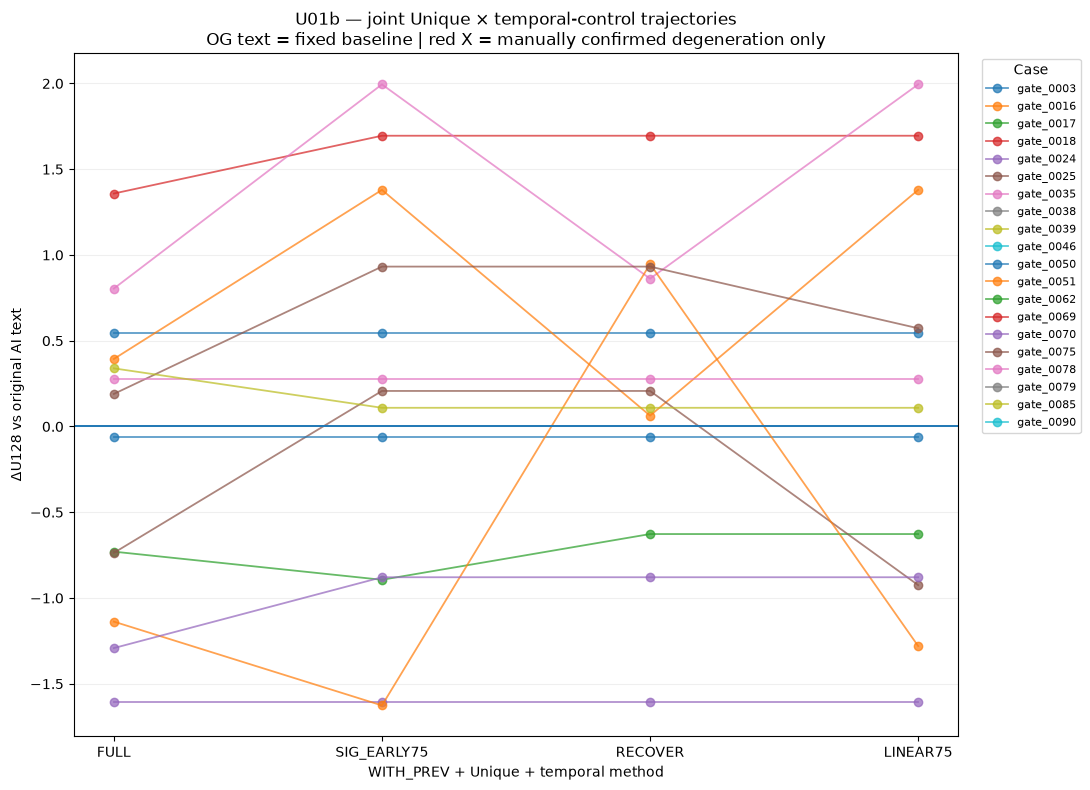

In [28]:
import matplotlib.pyplot as plt

DEGENERATE_KEYS=set()
# Example:
# DEGENERATE_KEYS={("gate_0051","SIG_EARLY75")}

scored["degenerate"]=[
    (str(r.case_id),str(r.method)) in DEGENERATE_KEYS
    for r in scored.itertuples(index=False)
]

method_order=["FULL","SIG_EARLY75","RECOVER","LINEAR75"]
x=np.arange(len(method_order))

fig,ax=plt.subplots(figsize=(11,8))
for cid,g in scored.groupby("case_id"):
    g=g.set_index("method").reindex(method_order)
    y=g.delta_U128.to_numpy(float)
    ax.plot(x,y,marker="o",linewidth=1.3,alpha=.72,label=cid)
    bad=g.degenerate.fillna(False).to_numpy(bool)&np.isfinite(y)
    if bad.any():
        ax.scatter(x[bad],y[bad],marker="x",s=145,linewidths=3,color="red",zorder=20)

ax.axhline(0,linewidth=1.4)
ax.set_xticks(x)
ax.set_xticklabels(method_order)
ax.set_xlabel("WITH_PREV + Unique + temporal method")
ax.set_ylabel("ΔU128 vs original AI text")
ax.set_title(
    "U01b — joint Unique × temporal-control trajectories\n"
    "OG text = fixed baseline | red X = manually confirmed degeneration only"
)
ax.grid(axis="y",alpha=.2)
ax.legend(bbox_to_anchor=(1.02,1),loc="upper left",fontsize=8,title="Case")
fig.tight_layout()
fig.savefig(OUT/"U01b_joint_deltaU_spaghetti.png",dpi=300,bbox_inches="tight")
plt.show()


## Interaction check against U01a (same WITH_PREV methods, no Unique)

If the U01a U128 file exists, compare each exact case/method before vs after adding Unique control.

This is the cleanest direct check that Unique and temporal control do not destructively interfere.


In [29]:
u01a_candidates=[
    U01A/"U128_all_generations.parquet",
    U01A/"U128_all_generations_checkpoint.parquet",
]
u01a_path=next((p for p in u01a_candidates if p.exists()),None)

if u01a_path is None:
    print("No scored U01a file found; joint outputs are complete, interaction comparison deferred.")
else:
    a=pd.read_parquet(u01a_path)
    a=a[a.context_mode.eq("WITH_PREV") & a.method.isin(METHODS)].copy()
    if "U128" not in a.columns:
        print("U01a file exists but has no U128 column:",u01a_path)
    else:
        cmp=scored.merge(
            a[["source_id","method","U128"]].rename(columns={"U128":"U128_no_unique"}),
            on=["source_id","method"],how="inner",validate="one_to_one"
        )
        cmp["delta_from_adding_unique"]=cmp.U128-cmp.U128_no_unique
        display(
            cmp.groupby("method")
            .agg(
                n=("delta_from_adding_unique","count"),
                mean_U_shift=("delta_from_adding_unique","mean"),
                median_U_shift=("delta_from_adding_unique","median"),
                mean_abs_U_shift=("delta_from_adding_unique",lambda x:float(np.abs(x).mean()))
            )
        )
        cmp.to_parquet(OUT/"U01b_vs_U01a_interaction.parquet",index=False)


,n,mean_U_shift,median_U_shift,mean_abs_U_shift
method,,,,
FULL,14,0.115910,0.000000,0.666863
LINEAR75,14,0.291509,0.083801,0.766798
RECOVER,14,0.208484,0.051281,0.879529
SIG_EARLY75,14,0.368840,0.000000,0.840404


,n,mean_temporal_effect,median_temporal_effect,negative_fraction,positive_fraction,mean_abs_temporal_effect
method,,,,,,
LINEAR75,14,0.124627,0.000000,0.285714,0.428571,0.362746
SIG_EARLY75,14,0.137040,0.000000,0.285714,0.428571,0.521900
RECOVER,14,0.164990,0.028923,0.214286,0.500000,0.503783


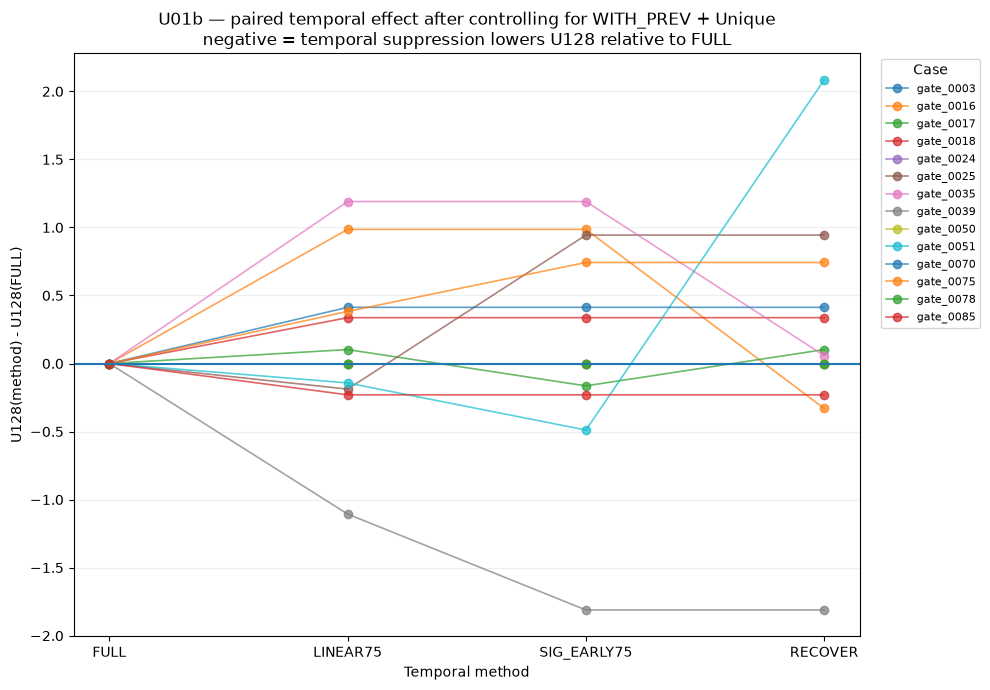

In [30]:
# Paired temporal effect relative to FULL:
#   temporal_effect_U128 = U128(method) - U128(FULL)
#
# Negative = temporal suppression lowered U128 relative to the exact
# WITH_PREV + Unique counterfactual for that same case.

wide = (
    scored[["case_id", "source_id", "method", "U128"]]
    .pivot(index=["case_id", "source_id"], columns="method", values="U128")
)

assert "FULL" in wide.columns
temporal_methods = ["LINEAR75", "SIG_EARLY75", "RECOVER"]

paired_rows = []

for method in temporal_methods:
    assert method in wide.columns, method

    z = wide[["FULL", method]].dropna().copy()
    z["temporal_effect_U128"] = z[method] - z["FULL"]

    for (case_id, source_id), r in z.iterrows():
        paired_rows.append({
            "case_id": case_id,
            "source_id": source_id,
            "method": method,
            "U128_FULL": r["FULL"],
            "U128_method": r[method],
            "temporal_effect_U128": r["temporal_effect_U128"],
        })

paired = pd.DataFrame(paired_rows)

paired_summary = (
    paired.groupby("method")
    .agg(
        n=("temporal_effect_U128", "count"),
        mean_temporal_effect=("temporal_effect_U128", "mean"),
        median_temporal_effect=("temporal_effect_U128", "median"),
        negative_fraction=(
            "temporal_effect_U128",
            lambda x: float((x < 0).mean())
        ),
        positive_fraction=(
            "temporal_effect_U128",
            lambda x: float((x > 0).mean())
        ),
        mean_abs_temporal_effect=(
            "temporal_effect_U128",
            lambda x: float(np.abs(x).mean())
        ),
    )
    .sort_values("mean_temporal_effect")
)

display(paired_summary)

paired.to_parquet(
    OUT / "U01b_temporal_vs_FULL_paired.parquet",
    index=False
)
paired_summary.to_csv(
    OUT / "U01b_temporal_vs_FULL_summary.csv"
)


# Paired plot: FULL is exactly zero for every case.
method_order = ["FULL", "LINEAR75", "SIG_EARLY75", "RECOVER"]
x = np.arange(len(method_order))

fig, ax = plt.subplots(figsize=(10, 7))

for cid, g in paired.groupby("case_id"):
    lookup = dict(
        zip(
            g["method"],
            g["temporal_effect_U128"]
        )
    )

    y = np.array([
        0.0,
        lookup.get("LINEAR75", np.nan),
        lookup.get("SIG_EARLY75", np.nan),
        lookup.get("RECOVER", np.nan),
    ])

    ax.plot(
        x,
        y,
        marker="o",
        linewidth=1.2,
        alpha=.72,
        label=cid,
    )

ax.axhline(0, linewidth=1.5)
ax.set_xticks(x)
ax.set_xticklabels(method_order)
ax.set_xlabel("Temporal method")
ax.set_ylabel("U128(method) - U128(FULL)")
ax.set_title(
    "U01b — paired temporal effect after controlling for WITH_PREV + Unique\n"
    "negative = temporal suppression lowers U128 relative to FULL"
)
ax.grid(axis="y", alpha=.2)
ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8,
    title="Case",
)
fig.tight_layout()

fig.savefig(
    OUT / "U01b_temporal_vs_FULL_paired.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    OUT / "U01b_temporal_vs_FULL_paired.pdf",
    bbox_inches="tight",
)

plt.show()

method,FULL,RECOVER,RECOVER_minus_FULL
case_id,,,
gate_0039,1.903632,0.092464,-1.811168
gate_0003,1.207284,1.207284,0.000000
gate_0051,0.944218,3.028787,2.084568


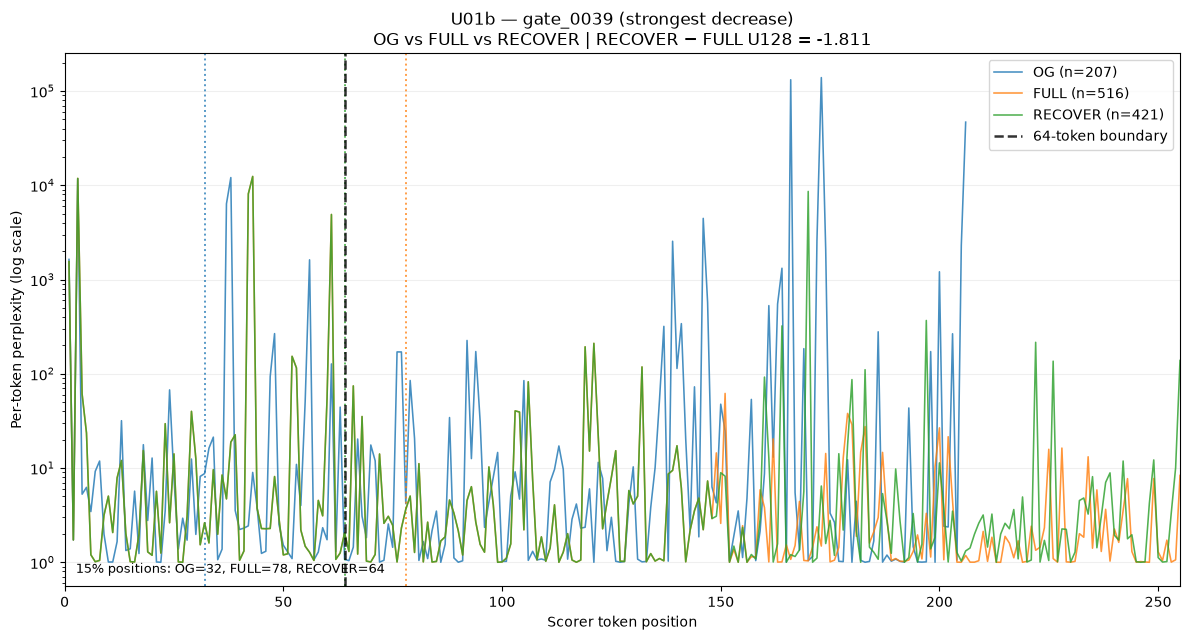

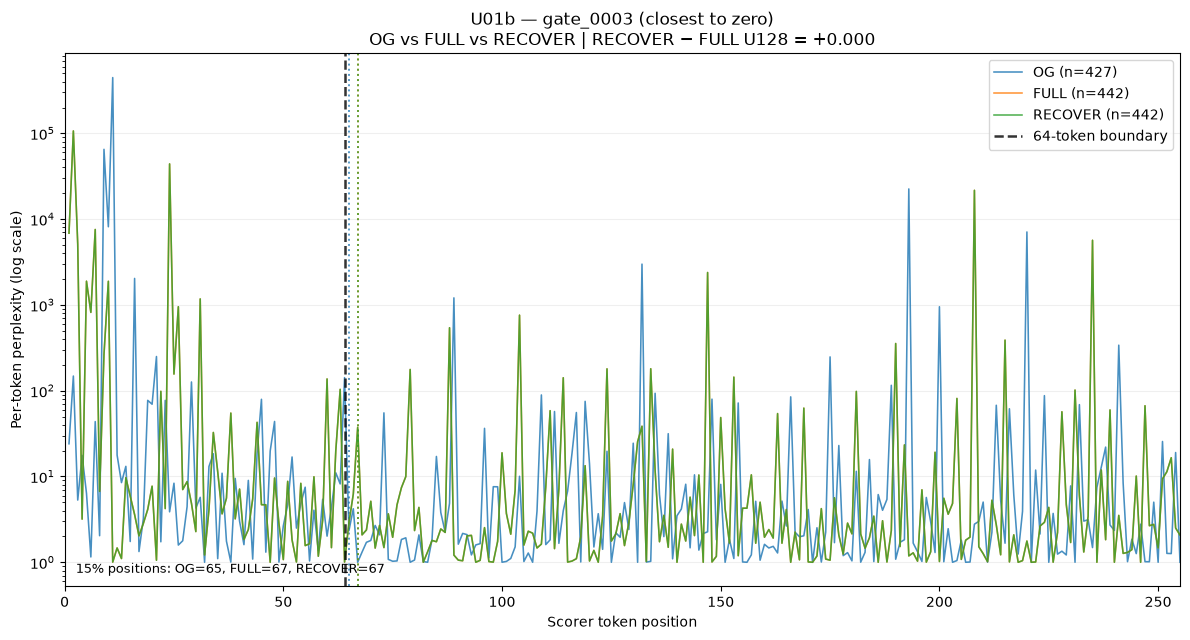

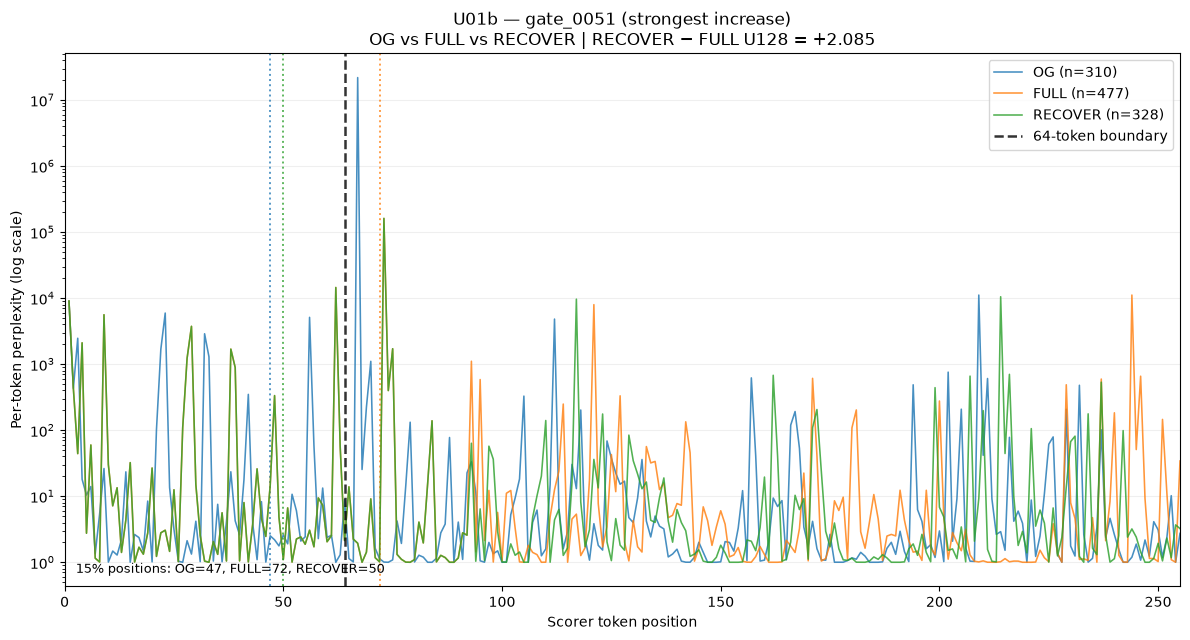

,case_id,condition,total_tokens,pct15_token,plotted_tokens
0,gate_0039,OG,207,32,207
1,gate_0039,FULL,516,78,256
2,gate_0039,RECOVER,421,64,256
3,gate_0003,OG,427,65,256
4,gate_0003,FULL,442,67,256
5,gate_0003,RECOVER,442,67,256
6,gate_0051,OG,310,47,256
7,gate_0051,FULL,477,72,256
8,gate_0051,RECOVER,328,50,256


In [31]:
# Per-token perplexity trajectories for 3 representative cases:
#   OG vs FULL vs RECOVER
#
# Cases are selected automatically as:
#   1) strongest RECOVER decrease relative to FULL
#   2) RECOVER effect closest to zero
#   3) strongest RECOVER increase relative to FULL
#
# Per-token perplexity is measured by the same frozen scorer used for U128.
# We show tokens 1..255 from the first 256 scorer tokens, matching the U128 span.
#
# Vertical markers:
#   dashed black = token 64 (temporal intervention begins)
#   dotted colored = 15% point for that particular text

assert "stok" in globals() and "smodel" in globals(), \
    "Run the U128 scorer-loading cell first."
assert "scored" in globals() and "cohort" in globals()

PLOT_TOKENS = 256

# ---------------------------------------------------------------------
# Select three representative cases from paired FULL vs RECOVER effect.
# ---------------------------------------------------------------------

u_wide = (
    scored.loc[
        scored["method"].isin(["FULL", "RECOVER"]),
        ["case_id", "method", "U128"]
    ]
    .pivot(index="case_id", columns="method", values="U128")
    .dropna(subset=["FULL", "RECOVER"])
)

u_wide["recover_effect"] = u_wide["RECOVER"] - u_wide["FULL"]

strong_down = u_wide["recover_effect"].idxmin()
near_zero = u_wide["recover_effect"].abs().idxmin()
strong_up = u_wide["recover_effect"].idxmax()

selected_cases = []
for cid in [strong_down, near_zero, strong_up]:
    if cid not in selected_cases:
        selected_cases.append(cid)

# Extremely unlikely tie safeguard: fill to 3 unique cases by distance from zero.
if len(selected_cases) < 3:
    for cid in u_wide["recover_effect"].abs().sort_values().index:
        if cid not in selected_cases:
            selected_cases.append(cid)
        if len(selected_cases) == 3:
            break

selected_cases = selected_cases[:3]

selection_labels = {
    strong_down: "strongest decrease",
    near_zero: "closest to zero",
    strong_up: "strongest increase",
}

display(
    u_wide.loc[selected_cases, ["FULL", "RECOVER", "recover_effect"]]
    .rename(columns={"recover_effect": "RECOVER_minus_FULL"})
)


# ---------------------------------------------------------------------
# Token-level scorer perplexity.
#
# For token i:
#   ppl_i = exp[-log p(x_i | x_<i)]
#
# Token 0 has no left-context prediction, so plotted positions begin at 1.
# ---------------------------------------------------------------------

@torch.inference_mode()
def token_perplexities(text, max_tokens=PLOT_TOKENS):
    all_ids = stok(
        str(text),
        add_special_tokens=False,
    )["input_ids"]

    n_total = len(all_ids)
    ids = all_ids[:max_tokens]

    if len(ids) < 2:
        return {
            "positions": np.array([], dtype=int),
            "ppl": np.array([], dtype=float),
            "n_total": n_total,
            "n_used": len(ids),
            "pct15": int(np.ceil(0.15 * n_total)),
        }

    x = torch.tensor(
        [ids],
        dtype=torch.long,
        device=device,
    )

    out = smodel(
        input_ids=x,
        use_cache=False,
    )

    # logits[:, t] predicts token t+1
    logits = out.logits[:, :-1, :].float()
    targets = x[:, 1:]

    losses = F.cross_entropy(
        logits.reshape(-1, logits.shape[-1]),
        targets.reshape(-1),
        reduction="none",
    )

    ppl = torch.exp(losses).detach().cpu().numpy()

    del out, logits, targets, losses, x

    return {
        "positions": np.arange(1, len(ids)),
        "ppl": ppl,
        "n_total": n_total,
        "n_used": len(ids),
        "pct15": int(np.ceil(0.15 * n_total)),
    }


# ---------------------------------------------------------------------
# Gather OG / FULL / RECOVER texts.
# ---------------------------------------------------------------------

og_lookup = (
    cohort[["case_id", "previous_ai"]]
    .drop_duplicates("case_id")
    .set_index("case_id")["previous_ai"]
)

def generated_text_for(case_id, method):
    z = scored.loc[
        scored["case_id"].astype(str).eq(str(case_id))
        & scored["method"].eq(method),
        "generated_text",
    ]
    assert len(z) == 1, (case_id, method, len(z))
    return z.iloc[0]


FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plot_records = []

for cid in selected_cases:
    texts = {
        "OG": og_lookup.loc[cid],
        "FULL": generated_text_for(cid, "FULL"),
        "RECOVER": generated_text_for(cid, "RECOVER"),
    }

    traces = {
        label: token_perplexities(text)
        for label, text in texts.items()
    }

    fig, ax = plt.subplots(figsize=(12, 6.5))

    # Plot raw per-token perplexity.
    line_colors = {}

    for label in ["OG", "FULL", "RECOVER"]:
        tr = traces[label]

        line, = ax.plot(
            tr["positions"],
            tr["ppl"],
            linewidth=1.15,
            alpha=.82,
            label=f"{label} (n={tr['n_total']})",
        )

        line_colors[label] = line.get_color()

        # Text-specific 15% boundary.
        p15 = tr["pct15"]

        if p15 <= PLOT_TOKENS:
            ax.axvline(
                p15,
                linestyle=":",
                linewidth=1.4,
                alpha=.75,
                color=line.get_color(),
            )

        plot_records.append({
            "case_id": cid,
            "condition": label,
            "total_tokens": tr["n_total"],
            "pct15_token": p15,
            "plotted_tokens": tr["n_used"],
        })

    # Temporal suppression begins after 64 generated tokens.
    ax.axvline(
        64,
        linestyle="--",
        linewidth=1.8,
        color="black",
        alpha=.8,
        label="64-token boundary",
    )

    effect = float(u_wide.loc[cid, "recover_effect"])
    role = selection_labels.get(cid, "representative")

    ax.set_xlim(0, PLOT_TOKENS - 1)

    # Raw token perplexities are extremely heavy-tailed; log scale preserves
    # individual token spikes without letting one spike flatten everything else.
    ax.set_yscale("log")

    ax.set_xlabel("Scorer token position")
    ax.set_ylabel("Per-token perplexity (log scale)")

    ax.set_title(
        f"U01b — {cid} ({role})\n"
        f"OG vs FULL vs RECOVER | "
        f"RECOVER − FULL U128 = {effect:+.3f}"
    )

    ax.grid(axis="y", alpha=.2)

    # Add explicit 15% positions to the graph.
    marker_text = "15% positions: " + ", ".join(
        f"{label}={traces[label]['pct15']}"
        for label in ["OG", "FULL", "RECOVER"]
    )

    ax.text(
        .01,
        .02,
        marker_text,
        transform=ax.transAxes,
        fontsize=9,
        va="bottom",
        ha="left",
    )

    ax.legend(loc="upper right")
    fig.tight_layout()

    stem = f"U01b_token_perplexity_{cid}_OG_FULL_RECOVER"

    fig.savefig(
        OUT / f"{stem}.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        OUT / f"{stem}.pdf",
        bbox_inches="tight",
    )

    fig.savefig(
        FIG_DIR / f"{stem}.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        FIG_DIR / f"{stem}.pdf",
        bbox_inches="tight",
    )

    plt.show()


display(pd.DataFrame(plot_records))

method,FULL,RECOVER,RECOVER_minus_FULL
case_id,,,
gate_0039,1.903632,0.092464,-1.811168
gate_0003,1.207284,1.207284,0.000000
gate_0051,0.944218,3.028787,2.084568


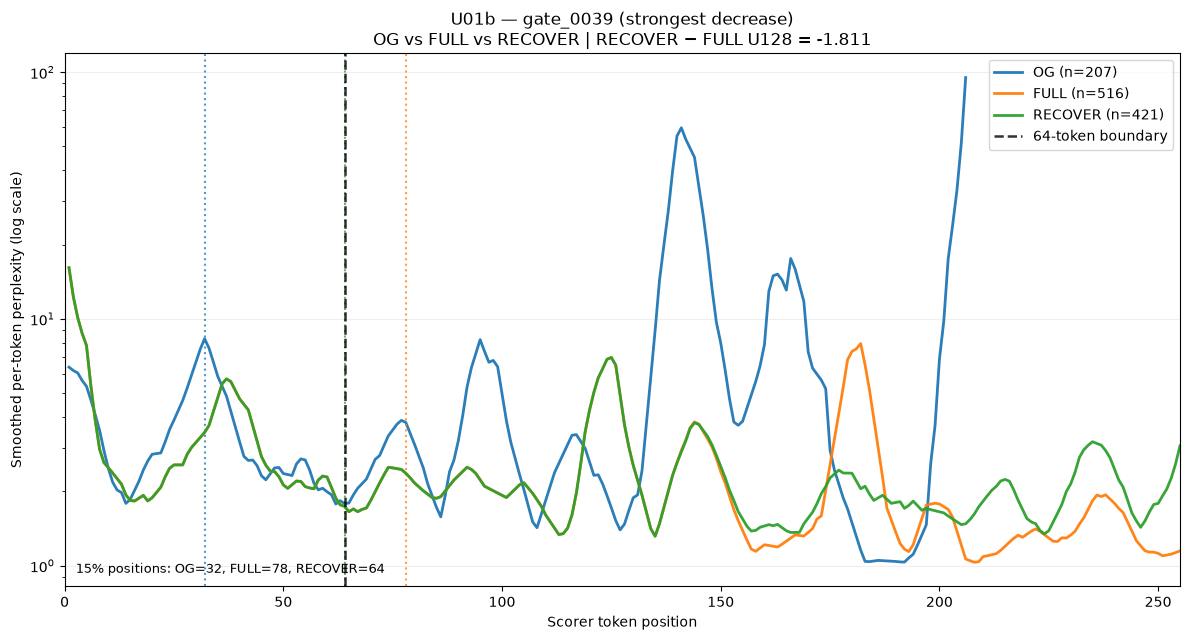

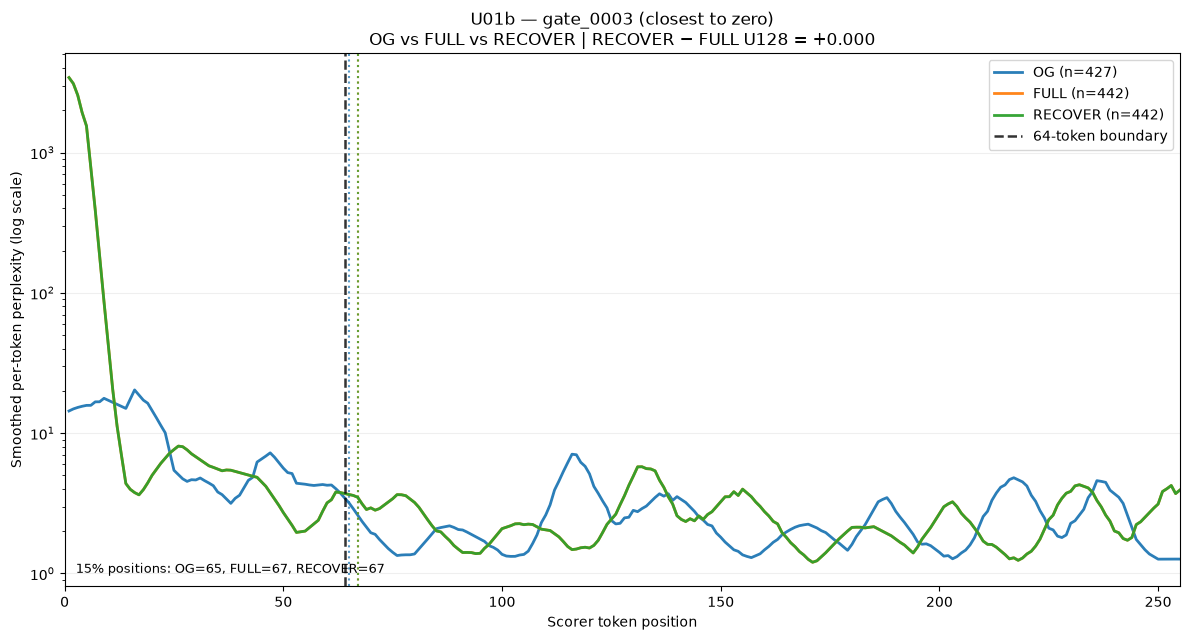

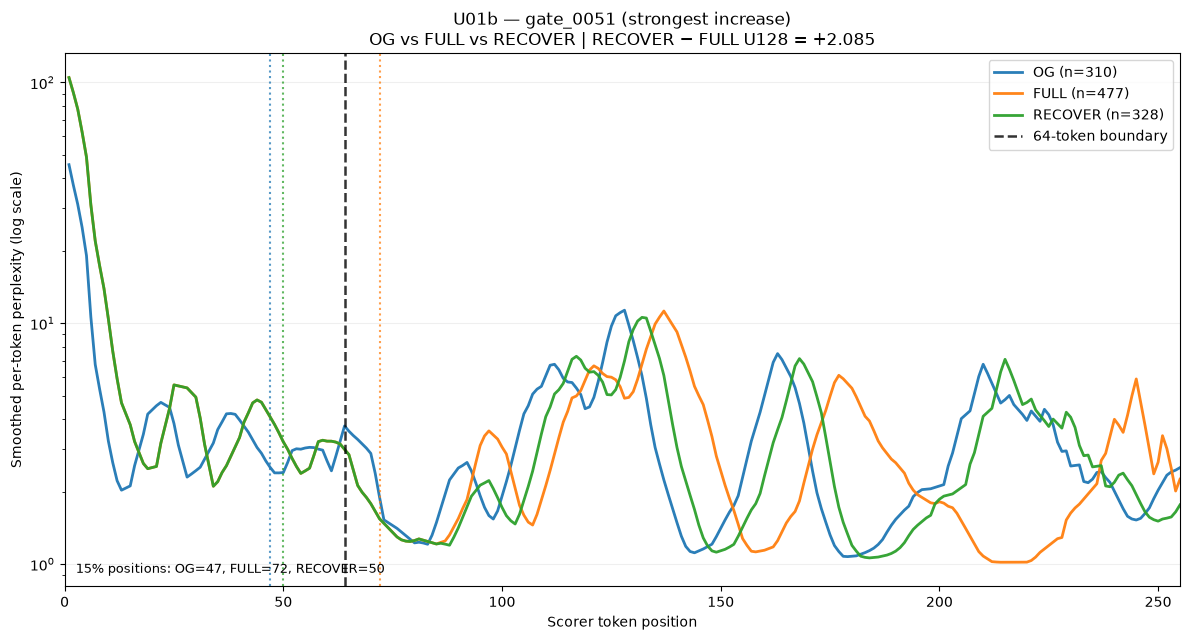

,case_id,condition,total_tokens,pct15_token,plotted_tokens
0,gate_0039,OG,207,32,207
1,gate_0039,FULL,516,78,256
2,gate_0039,RECOVER,421,64,256
3,gate_0003,OG,427,65,256
4,gate_0003,FULL,442,67,256
5,gate_0003,RECOVER,442,67,256
6,gate_0051,OG,310,47,256
7,gate_0051,FULL,477,72,256
8,gate_0051,RECOVER,328,50,256


In [32]:
# Smoothed per-token perplexity plots for 3 representative cases:
#   OG vs FULL vs RECOVER
#
# Smoothing:
#   1) take log10(perplexity)
#   2) centered rolling median
#   3) centered rolling mean
#   4) exponentiate back
#
# This keeps the heavy-tailed spikes from dominating the whole figure.

assert "stok" in globals() and "smodel" in globals(), \
    "Run the U128 scorer-loading cell first."
assert "scored" in globals() and "cohort" in globals()

PLOT_TOKENS = 256
MEDIAN_WINDOW = 9
MEAN_WINDOW = 9

# ---------------------------------------------------------------------
# Pick the same three representative cases from RECOVER vs FULL.
# ---------------------------------------------------------------------

u_wide = (
    scored.loc[
        scored["method"].isin(["FULL", "RECOVER"]),
        ["case_id", "method", "U128"]
    ]
    .pivot(index="case_id", columns="method", values="U128")
    .dropna(subset=["FULL", "RECOVER"])
)

u_wide["recover_effect"] = u_wide["RECOVER"] - u_wide["FULL"]

strong_down = u_wide["recover_effect"].idxmin()
near_zero = u_wide["recover_effect"].abs().idxmin()
strong_up = u_wide["recover_effect"].idxmax()

selected_cases = []
for cid in [strong_down, near_zero, strong_up]:
    if cid not in selected_cases:
        selected_cases.append(cid)

if len(selected_cases) < 3:
    for cid in u_wide["recover_effect"].abs().sort_values().index:
        if cid not in selected_cases:
            selected_cases.append(cid)
        if len(selected_cases) == 3:
            break

selected_cases = selected_cases[:3]

selection_labels = {
    strong_down: "strongest decrease",
    near_zero: "closest to zero",
    strong_up: "strongest increase",
}

display(
    u_wide.loc[selected_cases, ["FULL", "RECOVER", "recover_effect"]]
    .rename(columns={"recover_effect": "RECOVER_minus_FULL"})
)

# ---------------------------------------------------------------------
# Per-token perplexity from the frozen scorer.
# ---------------------------------------------------------------------

@torch.inference_mode()
def token_perplexities(text, max_tokens=PLOT_TOKENS):
    all_ids = stok(str(text), add_special_tokens=False)["input_ids"]
    n_total = len(all_ids)
    ids = all_ids[:max_tokens]

    if len(ids) < 2:
        return {
            "positions": np.array([], dtype=int),
            "ppl": np.array([], dtype=float),
            "n_total": n_total,
            "n_used": len(ids),
            "pct15": int(np.ceil(0.15 * n_total)),
        }

    x = torch.tensor([ids], dtype=torch.long, device=device)
    out = smodel(input_ids=x, use_cache=False)

    logits = out.logits[:, :-1, :].float()
    targets = x[:, 1:]

    losses = F.cross_entropy(
        logits.reshape(-1, logits.shape[-1]),
        targets.reshape(-1),
        reduction="none",
    )

    ppl = torch.exp(losses).detach().cpu().numpy()

    del out, logits, targets, losses, x

    return {
        "positions": np.arange(1, len(ids)),
        "ppl": ppl,
        "n_total": n_total,
        "n_used": len(ids),
        "pct15": int(np.ceil(0.15 * n_total)),
    }


def smooth_perplexity(ppl, median_window=MEDIAN_WINDOW, mean_window=MEAN_WINDOW):
    s = pd.Series(np.log10(np.maximum(np.asarray(ppl, float), 1e-12)))
    s = s.rolling(median_window, center=True, min_periods=1).median()
    s = s.rolling(mean_window, center=True, min_periods=1).mean()
    return np.power(10.0, s.to_numpy())


og_lookup = (
    cohort[["case_id", "previous_ai"]]
    .drop_duplicates("case_id")
    .set_index("case_id")["previous_ai"]
)

def generated_text_for(case_id, method):
    z = scored.loc[
        scored["case_id"].astype(str).eq(str(case_id))
        & scored["method"].eq(method),
        "generated_text",
    ]
    assert len(z) == 1, (case_id, method, len(z))
    return z.iloc[0]


FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plot_records = []

for cid in selected_cases:
    texts = {
        "OG": og_lookup.loc[cid],
        "FULL": generated_text_for(cid, "FULL"),
        "RECOVER": generated_text_for(cid, "RECOVER"),
    }

    traces = {label: token_perplexities(text) for label, text in texts.items()}

    fig, ax = plt.subplots(figsize=(12, 6.5))

    for label in ["OG", "FULL", "RECOVER"]:
        tr = traces[label]
        y = smooth_perplexity(tr["ppl"])

        line, = ax.plot(
            tr["positions"],
            y,
            linewidth=2.0,
            alpha=.95,
            label=f"{label} (n={tr['n_total']})",
        )

        p15 = tr["pct15"]
        if p15 <= PLOT_TOKENS:
            ax.axvline(
                p15,
                linestyle=":",
                linewidth=1.5,
                alpha=.75,
                color=line.get_color(),
            )

        plot_records.append({
            "case_id": cid,
            "condition": label,
            "total_tokens": tr["n_total"],
            "pct15_token": p15,
            "plotted_tokens": tr["n_used"],
        })

    ax.axvline(
        64,
        linestyle="--",
        linewidth=1.8,
        color="black",
        alpha=.8,
        label="64-token boundary",
    )

    effect = float(u_wide.loc[cid, "recover_effect"])
    role = selection_labels.get(cid, "representative")

    ax.set_xlim(0, PLOT_TOKENS - 1)
    ax.set_yscale("log")
    ax.set_xlabel("Scorer token position")
    ax.set_ylabel("Smoothed per-token perplexity (log scale)")
    ax.set_title(
        f"U01b — {cid} ({role})\n"
        f"OG vs FULL vs RECOVER | RECOVER − FULL U128 = {effect:+.3f}"
    )
    ax.grid(axis="y", alpha=.2)

    marker_text = "15% positions: " + ", ".join(
        f"{label}={traces[label]['pct15']}"
        for label in ["OG", "FULL", "RECOVER"]
    )
    ax.text(
        .01, .02, marker_text,
        transform=ax.transAxes,
        fontsize=9,
        va="bottom",
        ha="left",
    )

    ax.legend(loc="upper right")
    fig.tight_layout()

    stem = f"U01b_token_perplexity_smoothed_{cid}_OG_FULL_RECOVER"
    fig.savefig(OUT / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUT / f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{stem}.pdf", bbox_inches="tight")

    plt.show()

display(pd.DataFrame(plot_records))